In [28]:
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
prompt_df = pd.read_parquet('/data/mdicosta/DplusFlow/PbPb/MLTraining/Train603121/AO2D_HF_LHC25a5_medium_2P3PDstar_2050_O2hfcanddplite_prompt_cent_20_50.parquet')
fd_df = pd.read_parquet('/data/mdicosta/DplusFlow/PbPb/MLTraining/Train603121/AO2D_HF_LHC25a5_medium_2P3PDstar_2050_O2hfcanddplite_fd_cent_20_50.parquet')
data_df = pd.read_parquet('/data/mdicosta/DplusFlow/PbPb/MLTraining/Train599132/AO2D_HF_LHC23zzh_pass4_small_2P3PDstar_2050_O2hfcanddplite_data_cent_20_50.parquet')
data_df = data_df.query(f"fM < 1.74 or fM > 2.00")

In [30]:
# Small MC
# Prompt MC entries: 69042
# FD MC entries: 155831
# Data entries: 16233790

# Check for duplicates
print(f"Prompt MC entries: {len(prompt_df)}")
print(f"FD MC entries: {len(fd_df)}")
print(f"Data entries: {len(data_df)}")

Prompt MC entries: 180815
FD MC entries: 409037
Data entries: 16233790


Plotting fChi2PCA
Plotting fDecayLength
Plotting fDecayLengthXY
Plotting fDecayLengthNormalised
Plotting fDecayLengthXYNormalised
Plotting fPtProng0
Plotting fPtProng1
Plotting fPtProng2
Plotting fImpactParameter0
Plotting fImpactParameter1
Plotting fImpactParameter2
Plotting fImpactParameterZ0
Plotting fImpactParameterZ1
Plotting fImpactParameterZ2
Plotting fNSigTpcPi0
Plotting fNSigTpcKa0
Plotting fNSigTofPi0
Plotting fNSigTofKa0
Plotting fNSigTpcTofPi0
Plotting fNSigTpcTofKa0
Plotting fNSigTpcPi1
Plotting fNSigTpcKa1
Plotting fNSigTofPi1
Plotting fNSigTofKa1
Plotting fNSigTpcTofPi1
Plotting fNSigTpcTofKa1
Plotting fNSigTpcPi2
Plotting fNSigTpcKa2
Plotting fNSigTofPi2
Plotting fNSigTofKa2
Plotting fNSigTpcTofPi2
Plotting fNSigTpcTofKa2
Plotting fCandidateSelFlag
Plotting fM
Plotting fPt
Plotting fCpa
Plotting fCpaXY
Plotting fMaxNormalisedDeltaIP
Plotting fEta
Plotting fPhi
Plotting fY
Plotting fCentrality
Plotting fNumContrib
Plotting fFlagMcMatchRec
Plotting fOriginMcRec
Plotting f

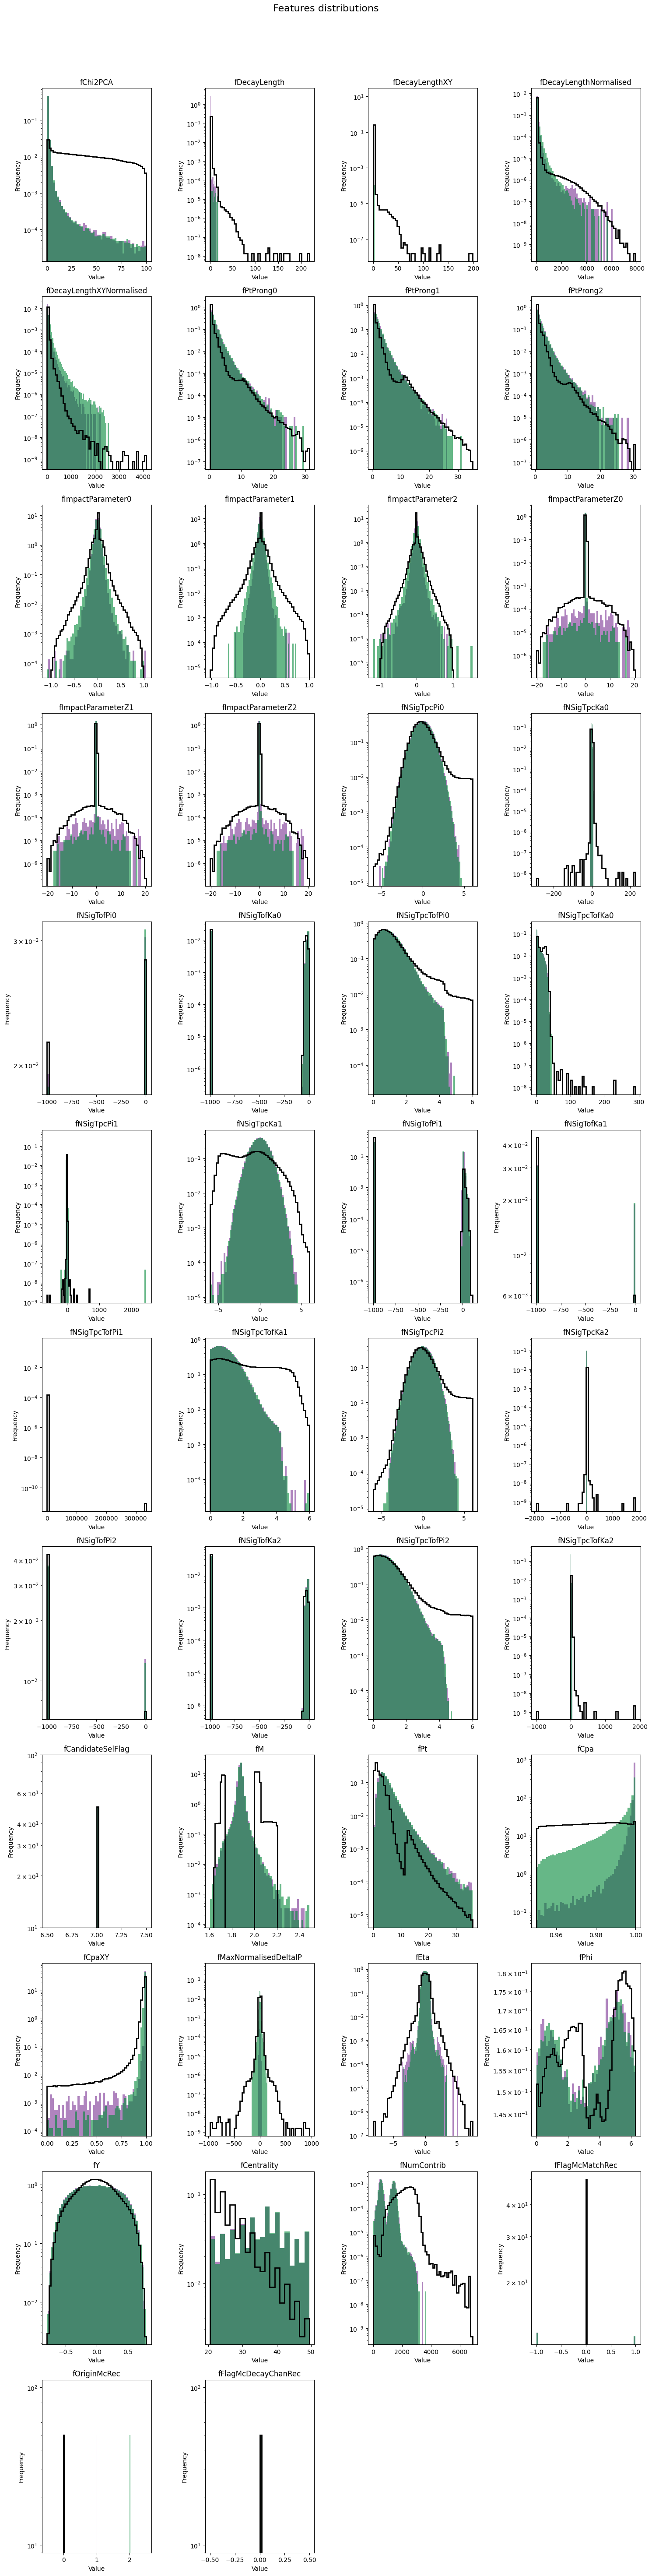

In [31]:
# Plot prompt, non-prompt and data sidebands distributions for all features
n_columns = len(data_df.columns)
n_rows = (n_columns // 4) + (1 if n_columns % 4 else 0)

fig, axes = plt.subplots(n_rows, 4, figsize=(15, 5 * n_rows))
axes = axes.flatten()
for i, column in enumerate(data_df.columns):
    print(f"Plotting {column}")
    try:
        if 'Centrality' in column:
            axes[i].hist(data_df[column].dropna(),   bins=20, density=True, color="black",   label="Data",   histtype="step", linewidth=2.0)
            axes[i].hist(prompt_df[column].dropna(), bins=20, density=True, color="#7b3294", label="Prompt", alpha=0.6) # Purples
            axes[i].hist(fd_df[column].dropna(),     bins=20, density=True, color="#008837", label="FD",     alpha=0.6) # Greens
        else:
            axes[i].hist(data_df[column].dropna(),   bins=50, density=True, color="black",   label="Data",   histtype="step", linewidth=2.0)
            axes[i].hist(prompt_df[column].dropna(), bins=50, density=True, color="#7b3294", label="Prompt", alpha=0.6)
            axes[i].hist(fd_df[column].dropna(),     bins=50, density=True, color="#008837", label="FD",     alpha=0.6)
        axes[i].set_title(f'{column}')
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Frequency')
        axes[i].set_yscale('log')
    except Exception as e:
        print(f"Could not plot column {column}: {e}")
        axes[i].set_visible(False)

# Remove unused axes if any
for i in range(n_columns, len(axes)):
    fig.delaxes(axes[i])

fig.suptitle("Features distributions", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [32]:
# Print column boundaries for all features for all dataframes
for column in data_df.columns:
    try:
        data_min, data_max = data_df[column].min(), data_df[column].max()
        prompt_min, prompt_max = prompt_df[column].min(), prompt_df[column].max()
        fd_min, fd_max = fd_df[column].min(), fd_df[column].max()
        print(f"Feature: {column}")
        print(f"  Data: ({data_min}, {data_max})")
        print(f"  Prompt MC: ({prompt_min}, {prompt_max})")
        print(f"  FD MC: ({fd_min}, {fd_max})")
    except Exception as e:
        print(f"Could not compute boundaries for column {column}: {e}")

Feature: fChi2PCA
  Data: (0.00014086432929616421, 99.99999237060547)
  Prompt MC: (0.0001374563289573416, 99.92877960205078)
  FD MC: (6.503269105451182e-05, 99.91759490966797)
Feature: fDecayLength
  Data: (0.05000000819563866, 218.35899353027344)
  Prompt MC: (0.05000061169266701, 18.301389694213867)
  FD MC: (0.050000231713056564, 17.621671676635742)
Feature: fDecayLengthXY
  Data: (1.8490860384190455e-05, 198.2266082763672)
  Prompt MC: (0.005339434370398521, 2.2178757190704346)
  FD MC: (0.004820690490305424, 3.361170768737793)
Feature: fDecayLengthNormalised
  Data: (3.6910102367401123, 7898.4716796875)
  Prompt MC: (6.4873948097229, 6061.36376953125)
  FD MC: (4.683011531829834, 5707.8984375)
Feature: fDecayLengthXYNormalised
  Data: (0.0049391877837479115, 4132.63330078125)
  Prompt MC: (1.109628677368164, 2232.179443359375)
  FD MC: (0.9148765206336975, 2573.758056640625)
Feature: fPtProng0
  Data: (0.4000000059604645, 31.234149932861328)
  Prompt MC: (0.40000826120376587, 26

Feature: fMaxNormalisedDeltaIP
  Data: (-963.7476806640625, 957.971923828125)
  Prompt MC: (-45.359832763671875, 52.50301742553711)
  FD MC: (-164.0771484375, 146.2572479248047)
Feature: fEta
  Data: (-8.164260864257812, 7.429112434387207)
  Prompt MC: (-3.695039987564087, 5.2038702964782715)
  FD MC: (-3.3776705265045166, 3.412898540496826)
Feature: fPhi
  Data: (1.2855939246492198e-07, 6.28318452835083)
  Prompt MC: (4.064932727487758e-05, 6.283169269561768)
  FD MC: (2.1020301574026234e-05, 6.283167362213135)
Feature: fY
  Data: (-0.7990509867668152, 0.7994194626808167)
  Prompt MC: (-0.7901507019996643, 0.7847244739532471)
  FD MC: (-0.792326807975769, 0.7886425852775574)
Feature: fCentrality
  Data: (20.5, 49.5)
  Prompt MC: (20.5, 49.5)
  FD MC: (20.5, 49.5)
Feature: fNumContrib
  Data: (2, 6879)
  Prompt MC: (29, 3464)
  FD MC: (20, 3686)
Feature: fFlagMcMatchRec
  Data: (0, 0)
  Prompt MC: (-1, 1)
  FD MC: (-1, 1)
Feature: fOriginMcRec
  Data: (0, 0)
  Prompt MC: (1, 1)
  FD MC

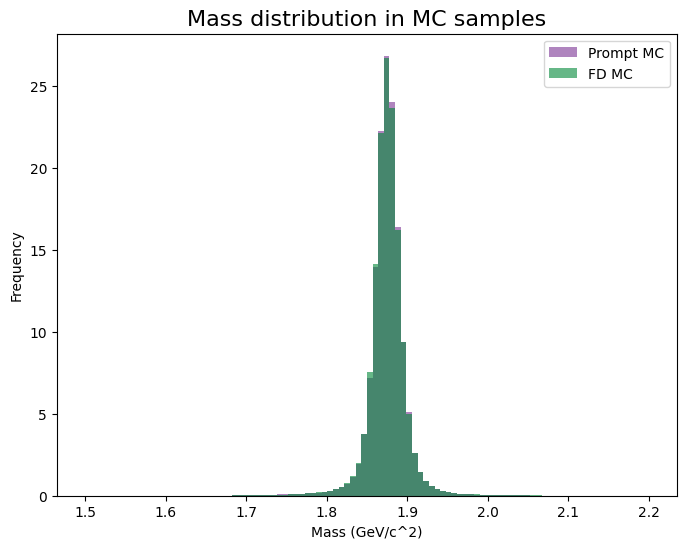

In [33]:
# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(prompt_df['fM'].dropna(), bins=100, color="#7b3294", density=True, range=(1.5, 2.2), alpha=0.6, label="Prompt MC")
plt.hist(fd_df['fM'].dropna(), bins=100, color="#008837", density=True, range=(1.5, 2.2), alpha=0.6, label="FD MC")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

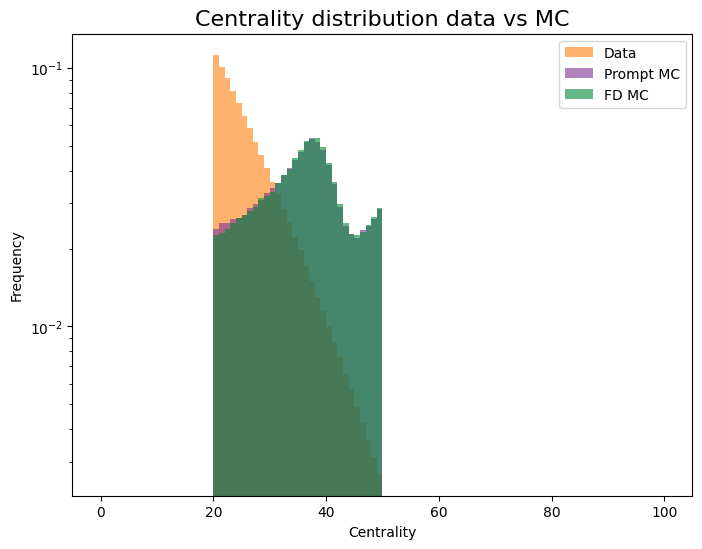

In [34]:
# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(data_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#ff7f0e", alpha=0.6, density=True, log=True, label="Data")
plt.hist(prompt_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#7b3294", alpha=0.6, density=True, log=True, label="Prompt MC")
plt.hist(fd_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#008837", alpha=0.6, density=True, log=True, label="FD MC")
plt.title("Centrality distribution data vs MC", fontsize=16)
plt.xlabel("Centrality")
plt.ylabel("Frequency")
plt.legend()
plt.show()

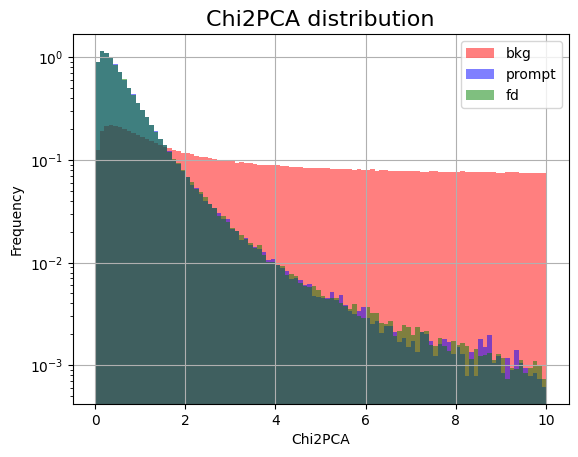

In [35]:
data_df['fChi2PCA'].hist(bins=100, color='red', alpha=0.5, range=(0,10), log=True, density=True, label='bkg')
prompt_df['fChi2PCA'].hist(bins=100, color='blue', alpha=0.5, range=(0,10), log=True, density=True, label='prompt')
fd_df['fChi2PCA'].hist(bins=100, color='green', alpha=0.5, range=(0,10), log=True, density=True, label='fd')
plt.title("Chi2PCA distribution", fontsize=16)
plt.xlabel("Chi2PCA")
plt.ylabel("Frequency")
plt.legend()
plt.show()

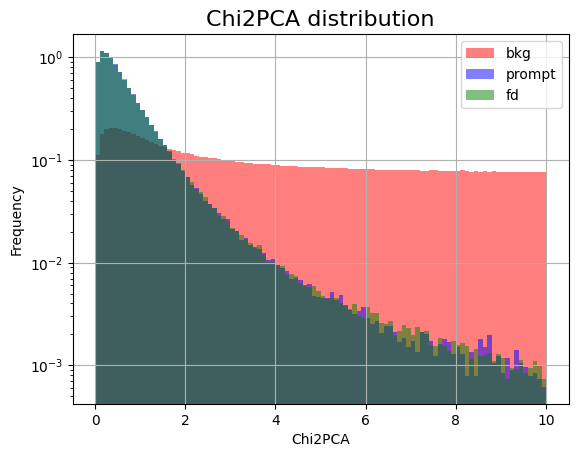

In [36]:
data_df.query('fDecayLength < 2')['fChi2PCA'].hist(bins=100, color='red', alpha=0.5, range=(0,10), log=True, density=True, label='bkg')
prompt_df.query('fDecayLength < 2')['fChi2PCA'].hist(bins=100, color='blue', alpha=0.5, range=(0,10), log=True, density=True, label='prompt')
fd_df.query('fDecayLength < 2')['fChi2PCA'].hist(bins=100, color='green', alpha=0.5, range=(0,10), log=True, density=True, label='fd')
plt.title("Chi2PCA distribution", fontsize=16)
plt.xlabel("Chi2PCA")
plt.ylabel("Frequency")
plt.legend()
plt.show()

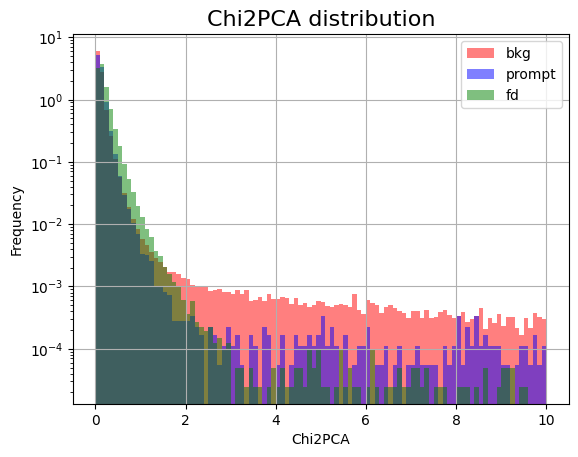

In [37]:
data_df['fDecayLength'].hist(bins=100, color='red', alpha=0.5, range=(0,10), log=True, density=True, label='bkg')
prompt_df['fDecayLength'].hist(bins=100, color='blue', alpha=0.5, range=(0,10), log=True, density=True, label='prompt')
fd_df['fDecayLength'].hist(bins=100, color='green', alpha=0.5, range=(0,10), log=True, density=True, label='fd')
plt.title("Chi2PCA distribution", fontsize=16)
plt.xlabel("Chi2PCA")
plt.ylabel("Frequency")
plt.legend()
plt.show()

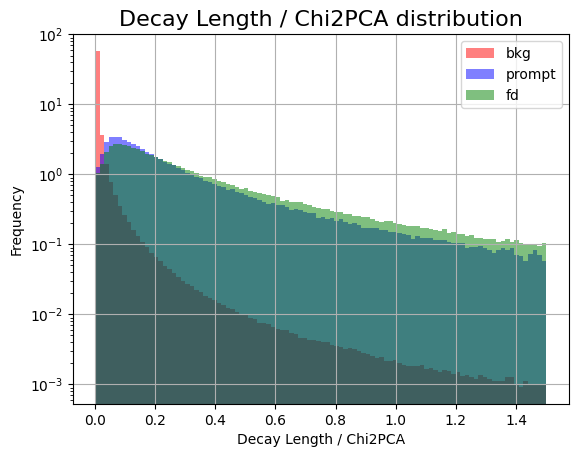

In [38]:
data_df['fDecayLength_div_fChi2PCA'] = data_df['fDecayLength'] / data_df['fChi2PCA']
data_df.query('fDecayLength < 2')['fDecayLength_div_fChi2PCA'].hist(bins=100, color='red', alpha=0.5, range=(0,1.5), log=True, density=True, label='bkg')
prompt_df['fDecayLength_div_fChi2PCA'] = prompt_df['fDecayLength'] / prompt_df['fChi2PCA']
prompt_df.query('fDecayLength < 2')['fDecayLength_div_fChi2PCA'].hist(bins=100, color='blue', alpha=0.5, range=(0,1.5), log=True, density=True, label='prompt')
fd_df['fDecayLength_div_fChi2PCA'] = fd_df['fDecayLength'] / fd_df['fChi2PCA']
fd_df.query('fDecayLength < 2')['fDecayLength_div_fChi2PCA'].hist(bins=100, color='green', alpha=0.5, range=(0,1.5), log=True, density=True, label='fd')
plt.title("Decay Length / Chi2PCA distribution", fontsize=16)
plt.xlabel("Decay Length / Chi2PCA")
plt.ylabel("Frequency")
plt.legend()
plt.show()

/home/mdicosta/virtenvpy/phys/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


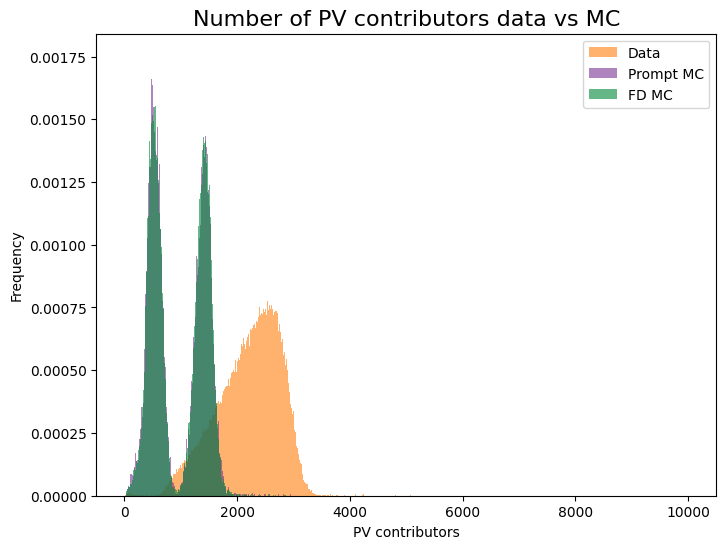

In [39]:
# Plot mass column of MC samples
import numpy as np
bins = np.arange(0, 10000, 1)

plt.figure(figsize=(8,6))
plt.hist(data_df['fNumContrib'].dropna(), bins=bins, color="#ff7f0e", density=True, alpha=0.6, label="Data") # , density=True # Orange color
plt.hist(prompt_df['fNumContrib'].dropna(), bins=bins, color="#7b3294", density=True, alpha=0.6, label="Prompt MC") # , density=True
plt.hist(fd_df['fNumContrib'].dropna(), bins=bins, color="#008837", density=True, alpha=0.6, label="FD MC") # , density=True
plt.title("Number of PV contributors data vs MC", fontsize=16)
plt.xlabel("PV contributors")
plt.ylabel("Frequency")
plt.legend()
plt.show()

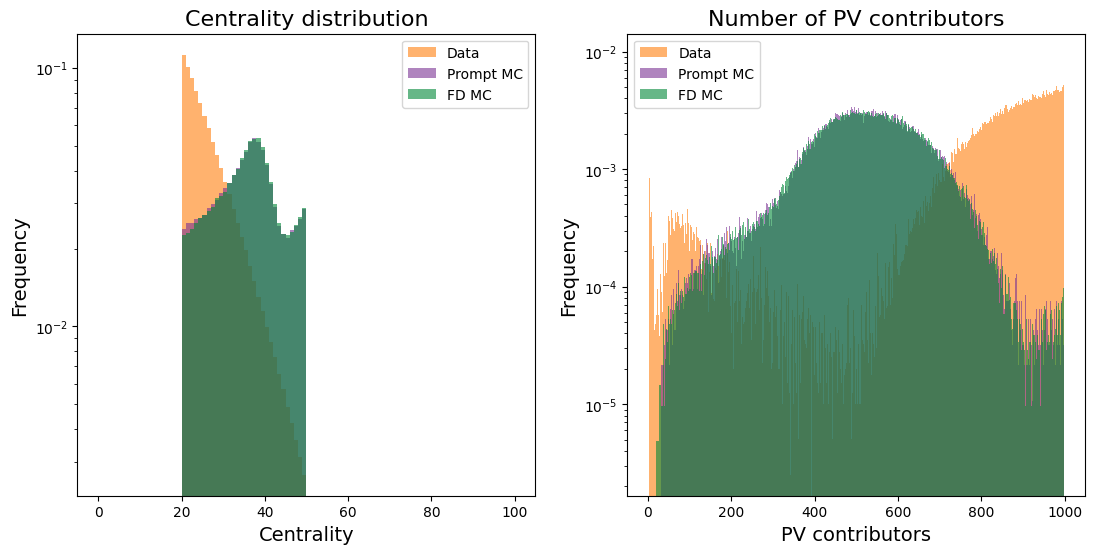

In [40]:
# Two panel figure with centrality and PV contributors
from matplotlib import gridspec
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
# Centrality
ax1.hist(data_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#ff7f0e", alpha=0.6, density=True, log=True, label="Data")
ax1.hist(prompt_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#7b3294", alpha=0.6, density=True, log=True, label="Prompt MC")
ax1.hist(fd_df['fCentrality'].dropna(), bins=100, range=(0,100), color="#008837", alpha=0.6, density=True, log=True, label="FD MC")
ax1.set_title("Centrality distribution", fontsize=16)
ax1.set_xlabel("Centrality", fontsize=14)
ax1.set_ylabel("Frequency", fontsize=14)
ax1.legend()
# PV contributors
bins = np.arange(0, 1000, 1)
ax2.hist(data_df['fNumContrib'].dropna(), bins=bins, color="#ff7f0e", density=True, log=True, alpha=0.6, label="Data") # , density=True # Orange color
ax2.hist(prompt_df['fNumContrib'].dropna(), bins=bins, color="#7b3294", density=True, log=True, alpha=0.6, label="Prompt MC") # , density=True
ax2.hist(fd_df['fNumContrib'].dropna(), bins=bins, color="#008837", density=True, log=True, alpha=0.6, label="FD MC") # , density=True
ax2.set_title("Number of PV contributors", fontsize=16)
ax2.set_xlabel("PV contributors", fontsize=14)
ax2.set_ylabel("Frequency", fontsize=14)
ax2.legend()
# plt.suptitle("Data vs MC feature comparison", fontsize=18)
# plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("cent_pvcontrib_comparison_MC_LHC25j10.pdf")
plt.show()

Feature: fNSigTpcTofPi2
  Data: (0.0, 5.999998569488525)
  Prompt MC: (0.0, 4.591198921203613)
  FD MC: (0.0, 4.7733306884765625)


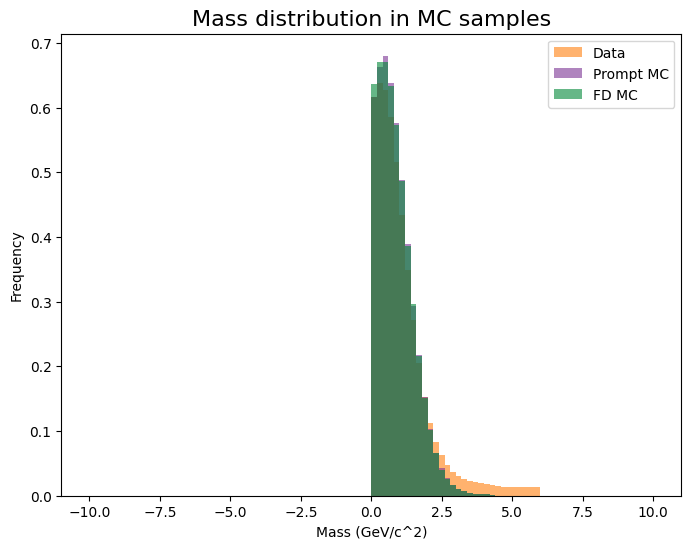

In [41]:
# Ranges for columns
data_min, data_max = data_df['fNSigTpcTofPi2'].min(), data_df['fNSigTpcTofPi2'].max()
prompt_min, prompt_max = prompt_df['fNSigTpcTofPi2'].min(), prompt_df['fNSigTpcTofPi2'].max()
fd_min, fd_max = fd_df['fNSigTpcTofPi2'].min(), fd_df['fNSigTpcTofPi2'].max()
print(f"Feature: fNSigTpcTofPi2")
print(f"  Data: ({data_min}, {data_max})")
print(f"  Prompt MC: ({prompt_min}, {prompt_max})")
print(f"  FD MC: ({fd_min}, {fd_max})")

# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(data_df['fNSigTpcTofPi2'].dropna(), bins=100, color="#ff7f0e", alpha=0.6, range=(-10,10), density=True, label="Data") # Orange color
plt.hist(prompt_df['fNSigTpcTofPi2'].dropna(), bins=100, color="#7b3294", alpha=0.6, range=(-10,10), density=True, label="Prompt MC")
plt.hist(fd_df['fNSigTpcTofPi2'].dropna(), bins=100, color="#008837", alpha=0.6, range=(-10,10), density=True, label="FD MC")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [ ]:
# Ranges for columns
data_min, data_max = data_df['fNSigTpcTofPi0'].min(), data_df['fNSigTpcTofPi0'].max()
prompt_min, prompt_max = prompt_df['fNSigTpcTofPi0'].min(), prompt_df['fNSigTpcTofPi0'].max()
fd_min, fd_max = fd_df['fNSigTpcTofPi0'].min(), fd_df['fNSigTpcTofPi0'].max()
print(f"Feature: fNSigTpcTofPi0")
print(f"  Data: ({data_min}, {data_max})")
print(f"  Prompt MC: ({prompt_min}, {prompt_max})")
print(f"  FD MC: ({fd_min}, {fd_max})")

# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(data_df['fNSigTpcTofPi0'].dropna(), bins=100, color="#ff7f0e", alpha=0.6, range=(0,10), density=True, label="Data") # Orange color
plt.hist(prompt_df['fNSigTpcTofPi0'].dropna(), bins=100, color="#7b3294", alpha=0.6, range=(0,10), density=True, label="Prompt MC")
plt.hist(fd_df['fNSigTpcTofPi0'].dropna(), bins=100, color="#008837", alpha=0.6, range=(0,10), density=True, label="FD MC")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

Feature: fNSigTpcTofPi0
  Data: (6.290906640060712e-07, 5.999998569488525)
  Prompt MC: (1.0719032616179902e-05, 4.757321357727051)
  FD MC: (2.6648367565940134e-06, 4.9417290687561035)


Feature: fNSigTpcTofKa1
  Data: (0.0, 5.999978065490723)
  Prompt MC: (1.313751818088349e-05, 5.794047832489014)
  FD MC: (1.0350696356908884e-05, 5.980875492095947)


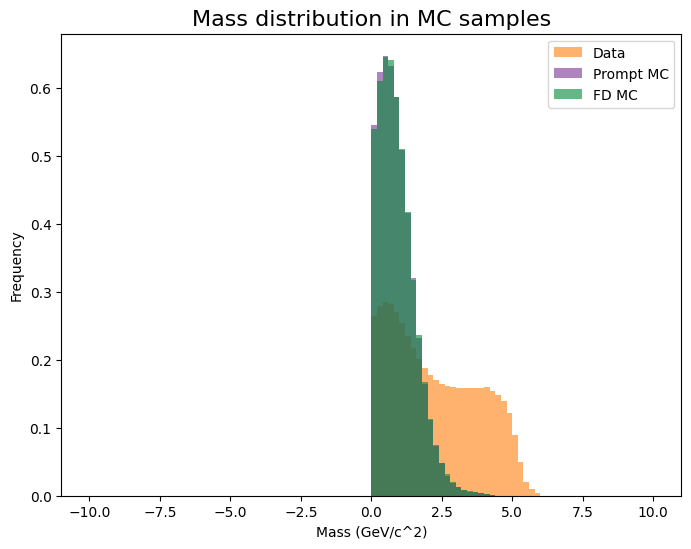

In [ ]:
# Ranges for columns
data_min, data_max = data_df['fNSigTpcTofKa1'].min(), data_df['fNSigTpcTofKa1'].max()
prompt_min, prompt_max = prompt_df['fNSigTpcTofKa1'].min(), prompt_df['fNSigTpcTofKa1'].max()
fd_min, fd_max = fd_df['fNSigTpcTofKa1'].min(), fd_df['fNSigTpcTofKa1'].max()
print(f"Feature: fNSigTpcTofKa1")
print(f"  Data: ({data_min}, {data_max})")
print(f"  Prompt MC: ({prompt_min}, {prompt_max})")
print(f"  FD MC: ({fd_min}, {fd_max})")

# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(data_df['fNSigTpcTofKa1'].dropna(), bins=100, color="#ff7f0e", alpha=0.6, range=(0,10), density=True, label="Data") # Orange color
plt.hist(prompt_df['fNSigTpcTofKa1'].dropna(), bins=100, color="#7b3294", alpha=0.6, range=(0,10), density=True, label="Prompt MC")
plt.hist(fd_df['fNSigTpcTofKa1'].dropna(), bins=100, color="#008837", alpha=0.6, range=(0,10), density=True, label="FD MC")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [ ]:
fd_df_pass3 = pd.read_parquet('/data/shared/DplFlowML/MLtrees/MC/Train319993/HF_LHC24g2_Medium_2P3PDstar_2050_NonPromptDplus.parquet')
prompt_df_pass3 = pd.read_parquet('/data/shared/DplFlowML/MLtrees/MC/Train319993/HF_LHC24g2_Medium_2P3PDstar_2050_PromptDplus.parquet')

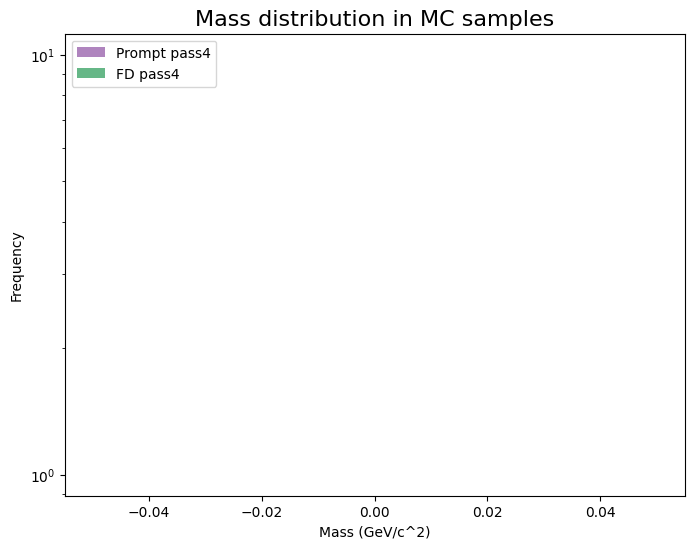

In [ ]:
# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(prompt_df['fNSigTpcTofPi0'].dropna(), bins=100, color="#7b3294", alpha=0.6, range=(0,200), log=True, density=True, label="Prompt pass4")
plt.hist(fd_df['fNSigTpcTofPi0'].dropna(), bins=100, color="#008837", alpha=0.6, range=(0,200), log=True, density=True, label="FD pass4")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

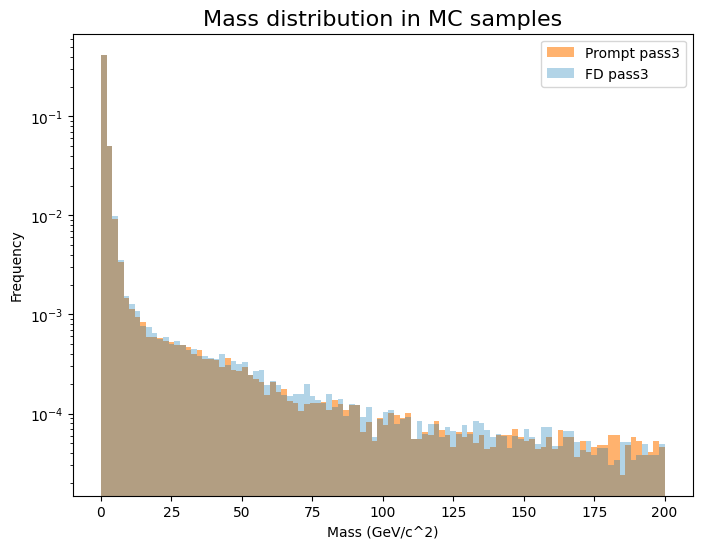

In [ ]:
# Plot mass column of MC samples
plt.figure(figsize=(8,6))
plt.hist(prompt_df_pass3['fNSigTpcTofPi0'].dropna(), bins=100, color="#ff7f0e", alpha=0.6, range=(0,200), log=True, density=True, label="Prompt pass3")
plt.hist(fd_df_pass3['fNSigTpcTofPi0'].dropna(), bins=100, color="#0173b2", alpha=0.3, range=(0,200), log=True, density=True, label="FD pass3")
plt.title("Mass distribution in MC samples", fontsize=16)
plt.xlabel("Mass (GeV/c^2)")
plt.ylabel("Frequency")
plt.legend()
plt.show()